In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("C:\\Users\\Medhya Khatri\\OneDrive\\Desktop\\Internship Task 4\\Amazon Product Reviews Dataset.csv")

df.head()


,marketplace,customer_id,review_id,product_id,product_parent,product_title,product_category,star_rating,helpful_votes,total_votes,vine,verified_purchase,review_headline,review_body,review_date,sentiment
0,US,11555559,R1QXC7AHHJBQ3O,B00IKPX4GY,2693241,"Fire HD 7, 7"" HD Display, Wi-Fi, 8 GB",PC,5,0,0,N,Y,Five Stars,Great love it,31-08-2015,1
1,US,31469372,R175VSRV6ZETOP,B00IKPYKWG,2693241,"Fire HD 7, 7"" HD Display, Wi-Fi, 8 GB",PC,3,0,0,N,N,Lots of ads Slow processing speed Occasionally...,Lots of ads<br />Slow processing speed<br />Oc...,31-08-2015,0
2,US,26843895,R2HRFF78MWGY19,B00IKPW0UA,2693241,"Fire HD 7, 7"" HD Display, Wi-Fi, 8 GB",PC,5,0,0,N,Y,Well thought out device,Excellent unit. The versatility of this table...,31-08-2015,1
3,US,19844868,R8Q39WPKYVSTX,B00LCHSHMS,2693241,"Fire HD 7, 7"" HD Display, Wi-Fi, 8 GB",PC,4,0,0,N,N,Not all apps/games we were looking forward to ...,I bought this on Amazon Prime so I ended up bu...,31-08-2015,1
4,US,1189852,R3RL4C8YP2ZCJL,B00IKPZ5V6,2693241,"Fire HD 7, 7"" HD Display, Wi-Fi, 8 GB",PC,5,0,0,N,Y,Five Stars,All Amazon products continue to meet my expect...,31-08-2015,1


In [2]:

print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDuplicate Rows:", df.duplicated().sum())


Dataset Shape: (30846, 16)

Missing Values:
review_headline    2
review_body        4
dtype: int64

Duplicate Rows: 0


In [5]:
df['review_headline'] = df['review_headline'].fillna('')
df['review_body'] = df['review_body'].fillna('')

In [6]:
print(df[['review_headline', 'review_body']].isnull().sum())

review_headline    0
review_body        0
dtype: int64


In [7]:
print(df['star_rating'].value_counts().sort_index())

star_rating
1     1708
2     1155
3     2216
4     5748
5    20019
Name: count, dtype: int64


In [8]:
print(df['sentiment'].value_counts(dropna=False))

sentiment
1    25767
0     5079
Name: count, dtype: int64


In [9]:
df['review_body'] = df['review_body'].str.lower().str.strip()
df['review_headline'] = df['review_headline'].str.lower().str.strip()

In [10]:
def classify_sentiment(rating):
    if rating >= 4:
        return 'Positive'
    elif rating == 3:
        return 'Neutral'
    else:
        return 'Negative'

df['Sentiment_Label'] = df['star_rating'].apply(classify_sentiment)

In [11]:
print(df['Sentiment_Label'].value_counts())

Sentiment_Label
Positive    25767
Negative     2863
Neutral      2216
Name: count, dtype: int64


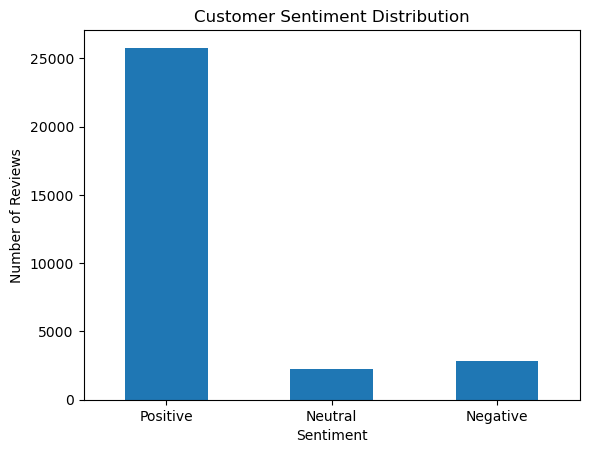

In [12]:
df['Sentiment_Label'].value_counts().reindex(
    ['Positive', 'Neutral', 'Negative']
).plot(kind='bar', title='Customer Sentiment Distribution')

plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=0)
plt.show()

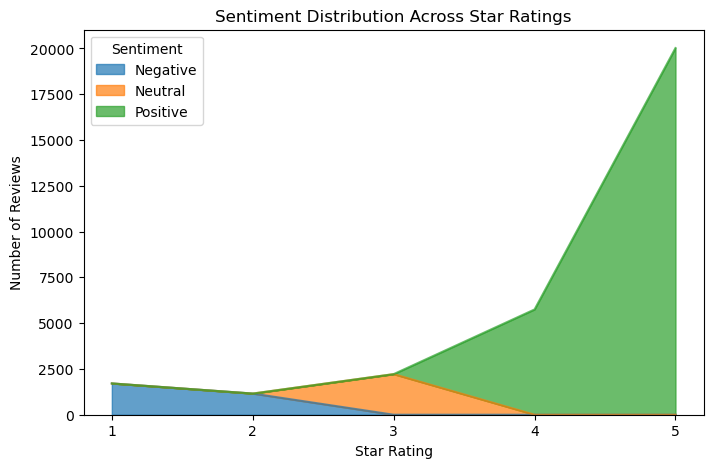

In [13]:
sentiment_rating = pd.crosstab(
    df['star_rating'],
    df['Sentiment_Label']
)

sentiment_rating.plot(
    kind='area',
    stacked=True,
    alpha=0.7,
    figsize=(8, 5)
)

plt.title('Sentiment Distribution Across Star Ratings')
plt.xlabel('Star Rating')
plt.ylabel('Number of Reviews')
plt.xticks([1, 2, 3, 4, 5])
plt.legend(title='Sentiment')
plt.show()

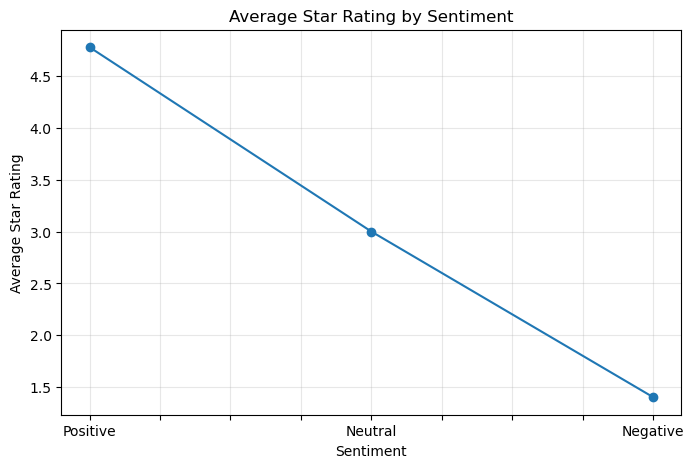

In [14]:
avg_rating = df.groupby('Sentiment_Label')['star_rating'].mean()

avg_rating = avg_rating.reindex(
    ['Positive', 'Neutral', 'Negative']
)

avg_rating.plot(
    kind='line',
    marker='o',
    figsize=(8, 5)
)

plt.title('Average Star Rating by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Average Star Rating')
plt.grid(True, alpha=0.3)
plt.show()

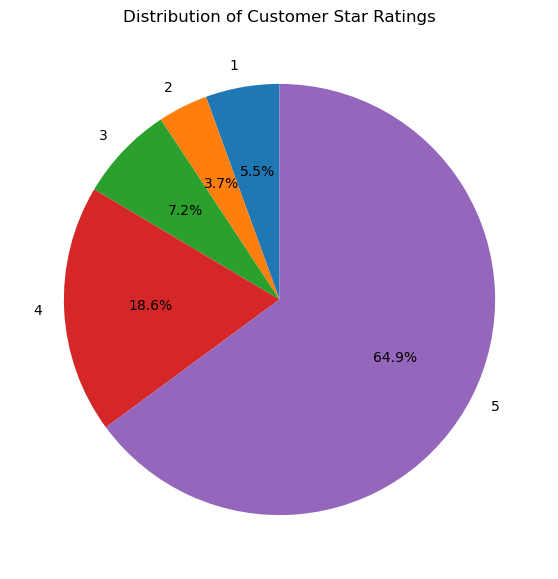

In [15]:
rating_counts = df['star_rating'].value_counts().sort_index()

rating_counts.plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(7, 7),
    startangle=90
)

plt.title('Distribution of Customer Star Ratings')
plt.ylabel('')
plt.show()

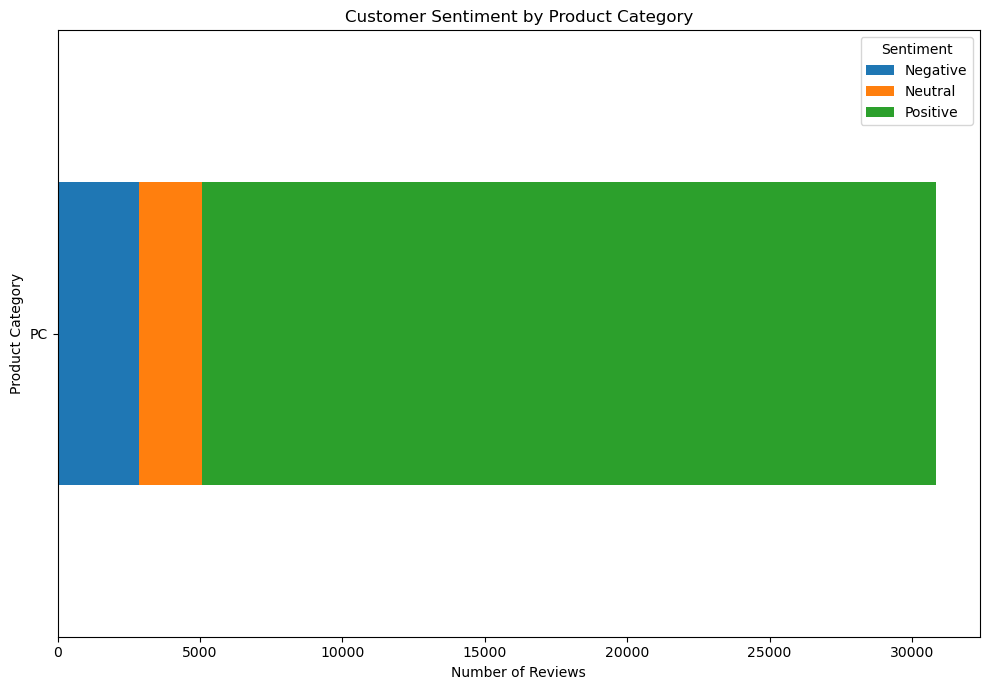

In [16]:
category_sentiment = pd.crosstab(
    df['product_category'],
    df['Sentiment_Label']
)

category_sentiment.plot(
    kind='barh',
    stacked=True,
    figsize=(10, 7)
)

plt.title('Customer Sentiment by Product Category')
plt.xlabel('Number of Reviews')
plt.ylabel('Product Category')
plt.legend(title='Sentiment')
plt.tight_layout()
plt.show()

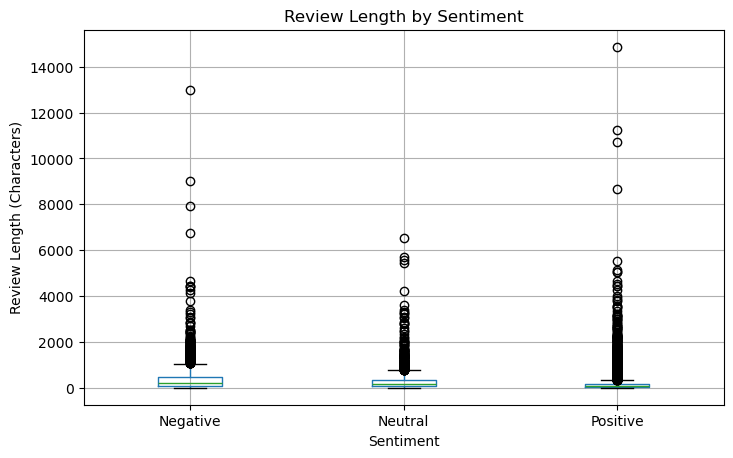

In [17]:
df['Review_Length'] = df['review_body'].str.len()

df.boxplot(
    column='Review_Length',
    by='Sentiment_Label',
    figsize=(8, 5)
)

plt.title('Review Length by Sentiment')
plt.suptitle('')
plt.xlabel('Sentiment')
plt.ylabel('Review Length (Characters)')
plt.show()

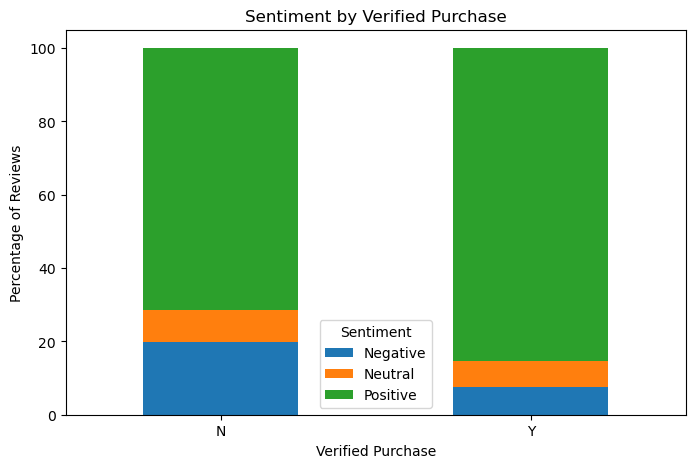

In [18]:
purchase_sentiment = pd.crosstab(
    df['verified_purchase'],
    df['Sentiment_Label'],
    normalize='index'
) * 100

purchase_sentiment.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5)
)

plt.title('Sentiment by Verified Purchase')
plt.xlabel('Verified Purchase')
plt.ylabel('Percentage of Reviews')
plt.legend(title='Sentiment')
plt.xticks(rotation=0)
plt.show()

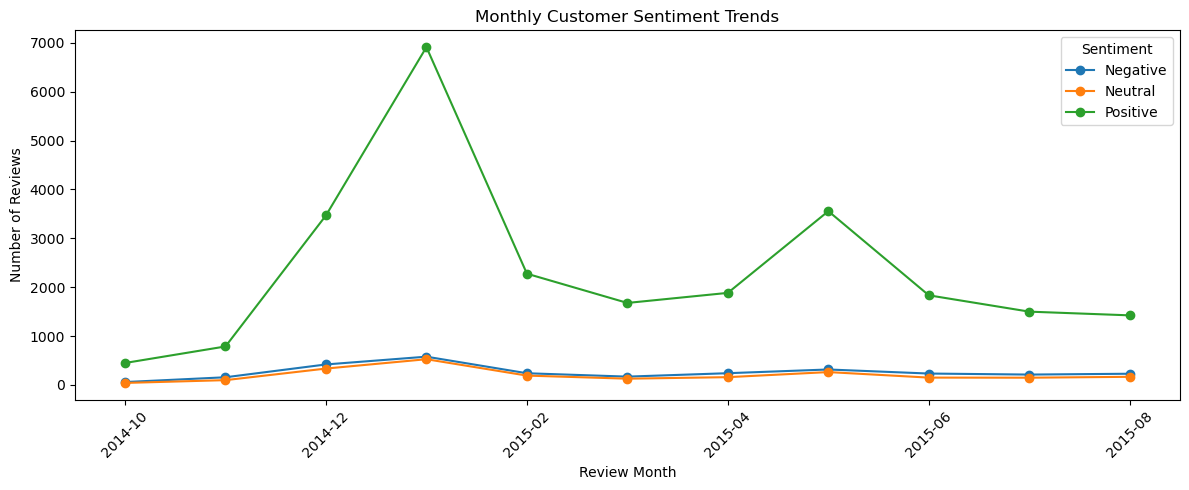

In [27]:
df['review_date'] = pd.to_datetime(
    df['review_date'], dayfirst=True, errors='coerce'
)

df['Review_Month'] = df['review_date'].dt.to_period('M').astype(str)

monthly_sentiment = pd.crosstab(
    df['Review_Month'],
    df['Sentiment_Label']
)

monthly_sentiment.plot(
    kind='line',
    figsize=(12, 5),
    marker='o'
)

plt.title('Monthly Customer Sentiment Trends')
plt.xlabel('Review Month')
plt.ylabel('Number of Reviews')
plt.legend(title='Sentiment')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

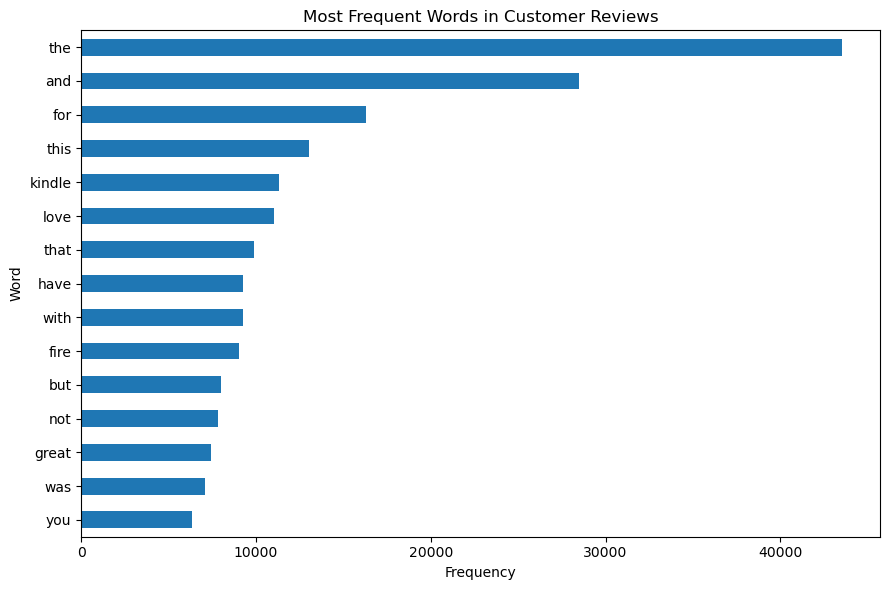

In [22]:
from collections import Counter
import re

text = ' '.join(df['review_body'].dropna())

words = re.findall(r'\b[a-z]{3,}\b', text)

common_words = Counter(words).most_common(15)

word_df = pd.DataFrame(common_words, columns=['Word', 'Frequency'])

word_df.sort_values('Frequency').plot(
    x='Word',
    y='Frequency',
    kind='barh',
    legend=False,
    figsize=(9, 6)
)

plt.title('Most Frequent Words in Customer Reviews')
plt.xlabel('Frequency')
plt.ylabel('Word')
plt.tight_layout()
plt.show()

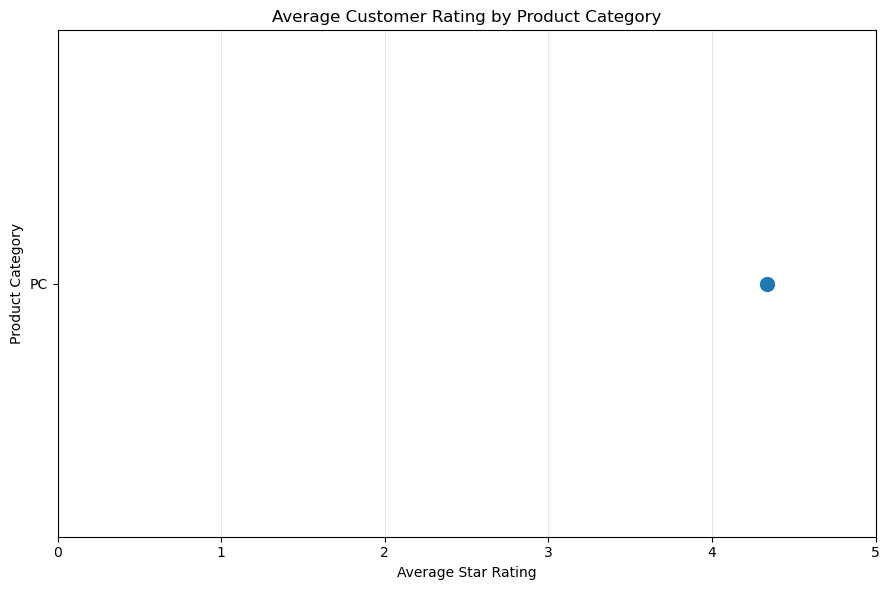

In [23]:
category_rating = df.groupby('product_category')['star_rating'].mean().sort_values()

plt.figure(figsize=(9, 6))
plt.scatter(category_rating.values, category_rating.index, s=100)

plt.title('Average Customer Rating by Product Category')
plt.xlabel('Average Star Rating')
plt.ylabel('Product Category')
plt.xlim(0, 5)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

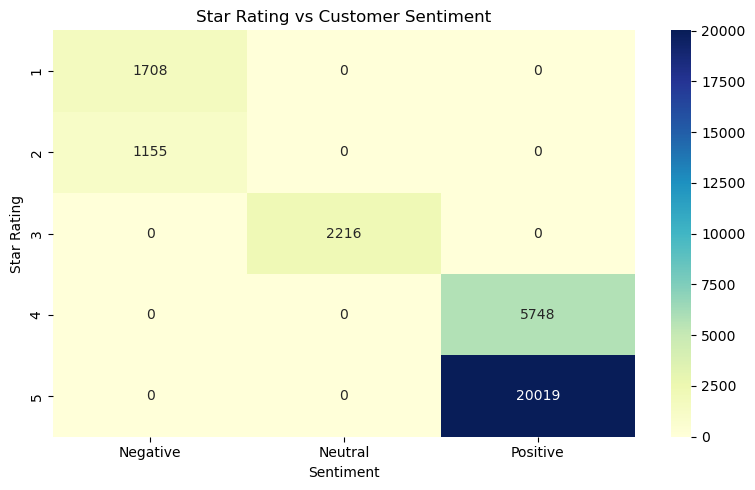

In [24]:
import seaborn as sns

rating_sentiment = pd.crosstab(
    df['star_rating'],
    df['Sentiment_Label']
)

plt.figure(figsize=(8, 5))
sns.heatmap(
    rating_sentiment,
    annot=True,
    fmt='d',
    cmap='YlGnBu'
)

plt.title('Star Rating vs Customer Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Star Rating')
plt.tight_layout()
plt.show()

In [25]:
df.to_csv("Amazon_Reviews_Sentiment_Analysis.csv", index=False)

In [26]:
print("Sentiment Distribution:")
print(df['Sentiment_Label'].value_counts())

print("\nAverage Rating by Product Category:")
print(
    df.groupby('product_category')['star_rating']
    .mean()
    .sort_values()
)

print("\nSentiment by Product Category:")
print(pd.crosstab(df['product_category'], df['Sentiment_Label']))

print("\nSentiment by Verified Purchase:")
print(pd.crosstab(df['verified_purchase'], df['Sentiment_Label']))

Sentiment Distribution:
Sentiment_Label
Positive    25767
Negative     2863
Neutral      2216
Name: count, dtype: int64

Average Rating by Product Category:
product_category
PC    4.336154
Name: star_rating, dtype: float64

Sentiment by Product Category:
Sentiment_Label   Negative  Neutral  Positive
product_category                             
PC                    2863     2216     25767

Sentiment by Verified Purchase:
Sentiment_Label    Negative  Neutral  Positive
verified_purchase                             
N                       798      343      2857
Y                      2065     1873     22910


## Key Findings and Insights

### 1. Sentiment Analysis
- Positive reviews were the most common, with **25,767 reviews**.
- There were **2,863 negative reviews** and **2,216 neutral reviews**.

### 2. Product Category Analysis
- The dataset contains reviews for the **PC** product category only.
- The average star rating for this category was approximately **4.34 out of 5**.
- A comparison between different product categories was not possible because only one category was present in the dataset.

### 3. Customer Feedback
- Verified purchases accounted for 22,910 positive reviews, 2,065 negative reviews, and 1,873 neutral reviews.
- Non-verified purchases accounted for 2,857 positive reviews, 798 negative reviews, and 343 neutral reviews.
- Positive reviews were the most common sentiment in both groups.

### 4. Product Improvement Recommendations
- Review negative customer feedback to identify recurring product issues.
- Use customer suggestions to improve product quality and user experience.
- Monitor neutral and negative reviews to identify opportunities to improve customer satisfaction.
- Continue tracking customer ratings and sentiment over time.